# Tugas Praktikum


## 1. Tugas K-Means


### Membaca Dataset burnout_dataset1.csv


In [1]:
import pandas as pd

df = pd.read_csv('burnout_dataset1.csv')
df.fillna(df.mean(numeric_only=True), inplace=True)

df.head()


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.000000,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.000000,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.000000,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.000000,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6251.281524,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


In [2]:
# Mengecek struktur datanya:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 40 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Person_ID                      50000 non-null  int64  
 1   Age                            50000 non-null  float64
 2   Gender                         50000 non-null  str    
 3   Country                        50000 non-null  str    
 4   Occupation                     50000 non-null  str    
 5   Education_Level                50000 non-null  str    
 6   Employment_Status              50000 non-null  str    
 7   Monthly_Income_USD             50000 non-null  float64
 8   Work_Hours_Per_Week            50000 non-null  int64  
 9   Remote_Work                    50000 non-null  str    
 10  Job_Satisfaction               50000 non-null  float64
 11  Work_Life_Balance              50000 non-null  float64
 12  Sleep_Hours                    50000 non-null  float64
 1

### Menentukan Fitur untuk Clustering


In [3]:
X = df[['Work_Hours_Per_Week', 'Burnout_Score']]

X.head()


,Work_Hours_Per_Week,Burnout_Score
0,67,82
1,44,64
2,60,50
3,25,16
4,52,26


Fitur Work_Hours_Per_Week dan Burnout_Score dipilih karena keduanya dapat menggambarkan pola beban kerja dan tingkat kejenuhan pekerja secara langsung.


### Melihat Persebaran Data


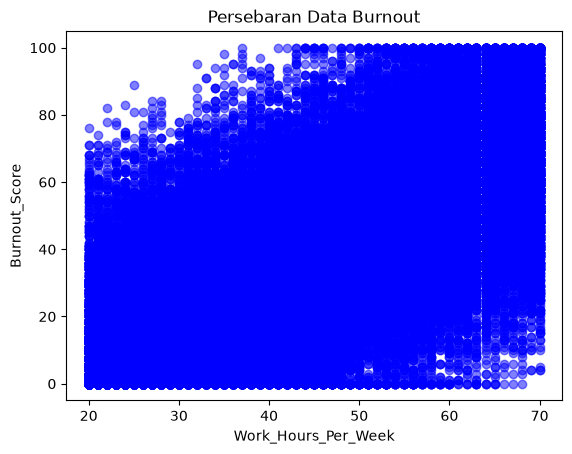

In [4]:
import matplotlib.pyplot as plt

plt.scatter(
    X['Work_Hours_Per_Week'],
    X['Burnout_Score'],
    color='blue',
    alpha=0.5
)
plt.xlabel('Work_Hours_Per_Week')
plt.ylabel('Burnout_Score')
plt.title('Persebaran Data Burnout')
plt.show()


Visualisasi awal ini digunakan untuk melihat pola persebaran data sebelum dilakukan clustering.


### Menentukan Jumlah k Terbaik


In [5]:
# Menggunakan Elbow Method
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)


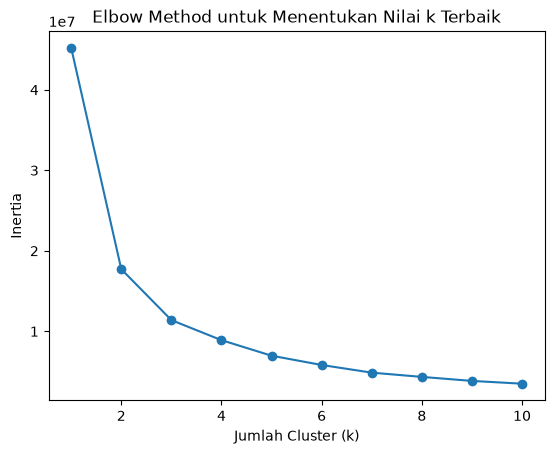

In [6]:
# Visualisasi
plt.plot(
    range(1, 11),
    inertia,
    marker='o'
)
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method untuk Menentukan Nilai k Terbaik')
plt.show()


Berdasarkan grafik Elbow Method, nilai k = 3 dipilih sebagai jumlah cluster yang digunakan karena setelah k = 3 penurunan inersia mulai melandai.


### Menentukan k


In [7]:
k = 3


### Membuat Model K-Means


In [8]:
kmeans = KMeans(
    n_clusters=3,
    random_state=0,
    n_init=10
)

labels = kmeans.fit_predict(X)


### Memasukkan Hasil Cluster ke Dataset


In [9]:
df['Cluster'] = labels

df.head()


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk,Cluster
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.000000,67,Hybrid,...,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High,2
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.000000,44,Hybrid,...,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate,2
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.000000,60,No,...,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate,1
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.000000,25,Yes,...,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low,0
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6251.281524,52,No,...,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low,1


In [10]:
# Melihat jumlah anggota setiap cluster
df['Cluster'].value_counts().sort_index()


Cluster
0    17880
1    19702
2    12418
Name: count, dtype: int64

### Memvisualisasi Hasil K-Means


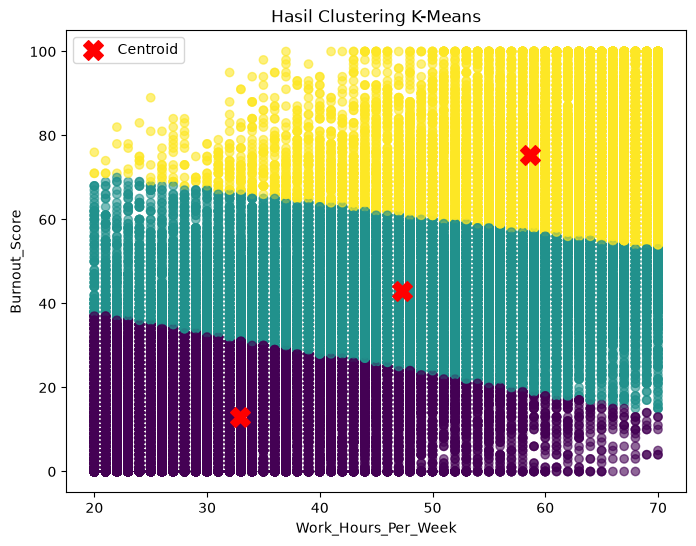

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X['Work_Hours_Per_Week'],
    X['Burnout_Score'],
    c=labels,
    cmap='viridis',
    alpha=0.6
)

# Menampilkan centroid
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=200,
    c='red',
    marker='X',
    label='Centroid'
)

plt.xlabel('Work_Hours_Per_Week')
plt.ylabel('Burnout_Score')
plt.title('Hasil Clustering K-Means')
plt.legend()
plt.show()


Berdasarkan hasil Elbow Method, diperoleh jumlah cluster terbaik yaitu k = 3. Pada titik tersebut, inersia mulai stabil dan pembagian kelompok pekerja berdasarkan jam kerja dan skor burnout dapat terpetakan dengan baik.


## 2. Tugas DBSCAN


### 1. Menyiapkan dataset burnout, lalu normalisasi.


In [12]:
# Import library untuk DBSCAN dan preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder


Membuat dataset


In [13]:
# Mengambil sampel data representatif sebanyak 1000 sampel untuk efisiensi DBSCAN
df_dbscan = df.sample(n=1000, random_state=0)
X_db = df_dbscan[['Work_Hours_Per_Week', 'Burnout_Score']].values
labels_true = LabelEncoder().fit_transform(df_dbscan['Burnout_Risk'])


Normalisasi data


In [14]:
# Melakukan standardisasi agar kedua fitur memiliki skala yang sebanding
X_scaled = StandardScaler().fit_transform(X_db)


Visualisasi dataset


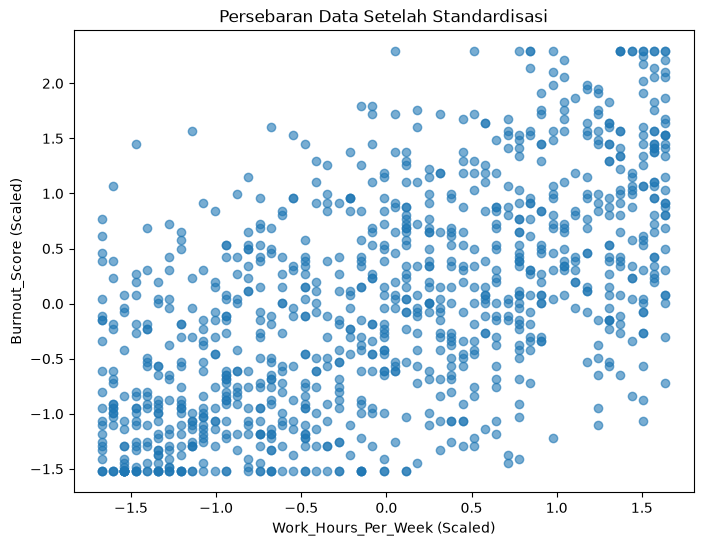

In [15]:
# Membuat scatter plot dataset
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], alpha=0.6)
plt.xlabel('Work_Hours_Per_Week (Scaled)')
plt.ylabel('Burnout_Score (Scaled)')
plt.title('Persebaran Data Setelah Standardisasi')
plt.show()


### 2. Menjalankan DBSCAN dengan eps=0.3, min_samples=10, hitung jumlah klaster & noise.


Membuat Model DBSCAN


In [16]:
# Import algoritma DBSCAN
from sklearn.cluster import DBSCAN

# Membuat dan menjalankan DBSCAN
db = DBSCAN(eps=0.3, min_samples=10).fit(X_scaled)
labels = db.labels_


Menghitung jumlah cluster dan noise


In [17]:
# Menghitung jumlah cluster dan mengabaikan label -1 (noise)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f'Jumlah cluster: {n_clusters_}')
print(f'Jumlah noise: {n_noise_}')


Jumlah cluster: 1
Jumlah noise: 16


### 3. Meng-evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette


In [18]:
# Import metrics untuk mengevaluasi hasil clustering
from sklearn import metrics


Menghitung metrik evaluasi


In [19]:
# Mengukur apakah setiap cluster hanya berisi anggota dari kelas yang sama
homogeneity = metrics.homogeneity_score(labels_true, labels)
completeness = metrics.completeness_score(labels_true, labels)
v_measure = metrics.v_measure_score(labels_true, labels)
ari = metrics.adjusted_rand_score(labels_true, labels)
ami = metrics.adjusted_mutual_info_score(labels_true, labels)
silhouette = metrics.silhouette_score(X_scaled, labels)

print(f'Homogeneity: {homogeneity:.3f}')
print(f'Completeness: {completeness:.3f}')
print(f'V-measure: {v_measure:.3f}')
print(f'Adjusted Rand Index: {ari:.3f}')
print(f'Adjusted Mutual Information: {ami:.3f}')
print(f'Silhouette: {silhouette:.3f}')


Homogeneity: 0.007
Completeness: 0.089
V-measure: 0.013
Adjusted Rand Index: 0.010
Adjusted Mutual Information: 0.011
Silhouette: 0.197


### 4. Mem-visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam)


Menentukan core sample


In [20]:
import numpy as np

# Membuat array boolean untuk menandai core sample
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True


Visualisasi


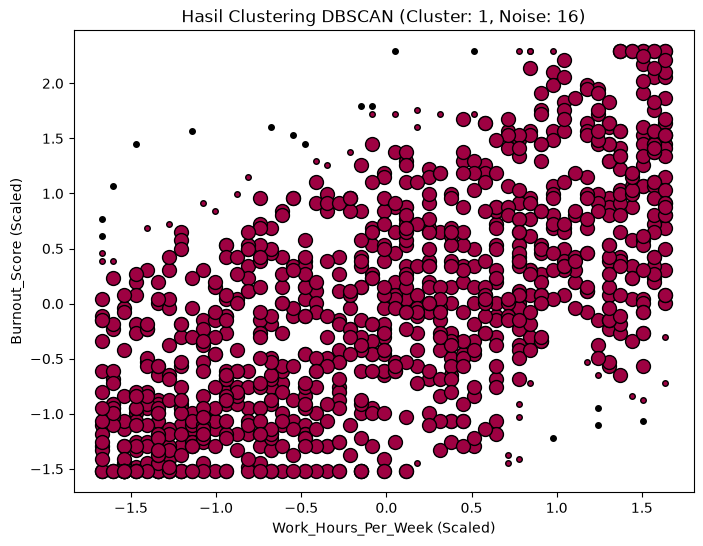

In [21]:
# Membuat area grafik
plt.figure(figsize=(8, 6))

# Melakukan perulangan untuk setiap cluster
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X_scaled[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=10,
    )

    xy = X_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        'o',
        markerfacecolor=tuple(col),
        markeredgecolor='k',
        markersize=4,
    )

plt.title(f'Hasil Clustering DBSCAN (Cluster: {n_clusters_}, Noise: {n_noise_})')
plt.xlabel('Work_Hours_Per_Week (Scaled)')
plt.ylabel('Burnout_Score (Scaled)')
plt.show()


### 5. Melakukan eksperimen


Menentukan parameter


In [22]:
# Daftar nilai eps yang akan diuji
eps_values = [0.1, 0.2, 0.3, 0.4]

# Daftar nilai min_samples yang akan diuji
min_samples_values = [5, 10, 15]


Menjalankan semua kombinasi


In [23]:
# List untuk menyimpan seluruh hasil eksperimen
results = []

# Mencoba setiap nilai eps
for eps in eps_values:
    # Mencoba setiap nilai min_samples
    for min_samples in min_samples_values:
        # Membuat dan melatih model DBSCAN
        db_exp = DBSCAN(eps=eps, min_samples=min_samples).fit(X_scaled)
        labels_exp = db_exp.labels_

        # Menghitung jumlah cluster (mengabaikan noise)
        n_clusters_exp = len(set(labels_exp)) - (1 if -1 in labels_exp else 0)

        # Menghitung jumlah titik noise
        n_noise_exp = list(labels_exp).count(-1)

        # Menghitung silhouette score hanya jika ada lebih dari 1 cluster dan tidak semua titik adalah noise
        if n_clusters_exp > 1:
            silhouette_exp = metrics.silhouette_score(X_scaled, labels_exp)
        else:
            silhouette_exp = None

        # Menyimpan konfigurasi parameter dan hasil evaluasi ke dalam list
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': n_clusters_exp,
            'n_noise': n_noise_exp,
            'silhouette': silhouette_exp,
        })


Membuat tabel hasil eksperimen


In [24]:
# Mengubah hasil eksperimen menjadi DataFrame
results_df = pd.DataFrame(results)
results_df


,eps,min_samples,n_clusters,n_noise,silhouette
0,0.1,5,47,418,-0.096995
1,0.1,10,2,935,0.034869
2,0.1,15,2,957,0.122621
3,0.2,5,2,26,0.028095
4,0.2,10,5,116,-0.272478
5,0.2,15,10,325,-0.001069
6,0.3,5,1,4,NaN
7,0.3,10,1,16,NaN
8,0.3,15,1,32,NaN
9,0.4,5,1,3,NaN


Berdasarkan hasil eksperimen, parameter eps dan min_samples mempengaruhi pembentukan klaster dan jumlah noise secara signifikan pada dataset burnout.
